In [9]:
!pip install -q mne openneuro-py specparam

In [10]:
import openneuro as on
from pathlib import Path

on.download(dataset="ds002778", target_dir="ds002778", include=["sub-pd3"])

for p in sorted(Path("ds002778/sub-pd3").rglob("*")):
    if p.is_file():
        print(p, f"{p.stat().st_size / 1e6:.1f} MB")

🌍 Preparing to download ds002778 …
📥 Checking 19 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds002778 (downloaded 0 files and 0 B).
ds002778/sub-pd3/ses-off/beh/sub-pd3_ses-off_task-rest_beh.json 0.0 MB
ds002778/sub-pd3/ses-off/beh/sub-pd3_ses-off_task-rest_beh.tsv 0.0 MB
ds002778/sub-pd3/ses-off/eeg/sub-pd3_ses-off_task-rest_channels.tsv 0.0 MB
ds002778/sub-pd3/ses-off/eeg/sub-pd3_ses-off_task-rest_eeg.bdf 12.6 MB
ds002778/sub-pd3/ses-off/eeg/sub-pd3_ses-off_task-rest_eeg.json 0.0 MB
ds002778/sub-pd3/ses-off/eeg/sub-pd3_ses-off_task-rest_events.tsv 0.0 MB
ds002778/sub-pd3/ses-off/sub-pd3_ses-off_scans.tsv 0.0 MB
ds002778/sub-pd3/ses-on/beh/sub-pd3_ses-on_task-rest_beh.json 0.0 MB
ds002778/sub-pd3/ses-on/beh/sub-pd3_ses-on_task-rest_beh.tsv 0.0 MB
ds002778/sub-pd3/ses-on/eeg/sub-pd3_ses-on_task-rest_channels.tsv 0.0 MB
ds002778/sub-pd3/ses-on/eeg/sub-pd3_ses-on_task-rest_eeg.bdf 13.4 MB
ds002778/sub-pd3/ses-on/eeg/sub-pd3_ses-on_task-rest_eeg.json 0.0 MB
ds002778/sub-pd3/ses-on/eeg/sub-pd3_ses-on_task-rest_events.tsv 0.0 MB
ds002778/sub-pd3/ses-on/sub-pd

In [11]:
import mne

READERS = {
    ".bdf": mne.io.read_raw_bdf,
    ".edf": mne.io.read_raw_edf,
    ".set": mne.io.read_raw_eeglab,
    ".vhdr": mne.io.read_raw_brainvision,
}

def load(session):
    for p in sorted(Path(f"ds002778/sub-pd3/ses-{session}").rglob("*")):
        if p.suffix in READERS:
            return READERS[p.suffix](p, preload=True)

raw_off, raw_on = load("off"), load("on")

print(raw_off.info)
print("Duration (s):", raw_off.times[-1])
print(raw_off.ch_names)

Extracting BDF parameters from ds002778/sub-pd3/ses-off/eeg/sub-pd3_ses-off_task-rest_eeg.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 102399  =      0.000 ...   199.998 secs...
Extracting BDF parameters from ds002778/sub-pd3/ses-on/eeg/sub-pd3_ses-on_task-rest_eeg.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 109055  =      0.000 ...   212.998 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AF3, F7, F3, FC1, FC5, T7, C3, CP1, CP5, P7, P3, Pz, PO3, ...
 chs: 40 EEG, 1 Stimulus
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 104.0 Hz
 meas_date: 2011-02-02 10:46:25 UTC
 nchan: 41
 projs: []
 sfreq: 512.0 Hz
 subject_info: <subject_info | his_id: >
>
Duration (s): 199.998046875
['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'Pz', 'PO3', 'O1', 'Oz', 'O2', 'PO4', 'P4', 'P8', 'CP6', 'CP2', 'C4', 'T8', 'FC6', 'FC2', 'F4', 'F8', 'AF4', 'Fp2', 'Fz', 'Cz', 'EXG1',

Using channels: ['C3', 'Cz', 'C4']
Effective window size : 2.000 (s)
Effective window size : 2.000 (s)


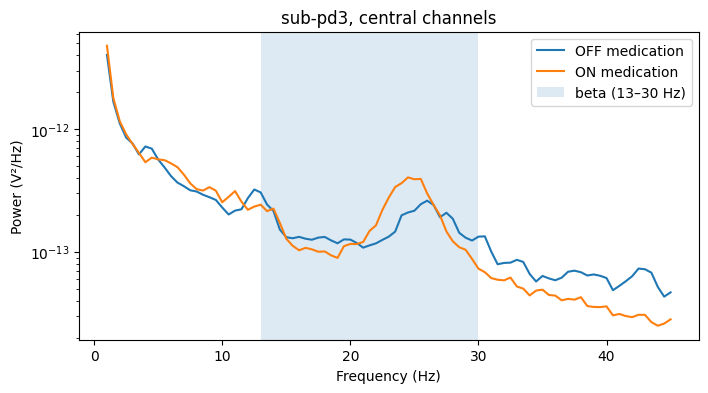

In [12]:
import matplotlib.pyplot as plt

picks = [ch for ch in ("C3", "Cz", "C4") if ch in raw_off.ch_names]
print("Using channels:", picks)

fig, ax = plt.subplots(figsize=(8, 4))
for raw, label in [(raw_off, "OFF medication"), (raw_on, "ON medication")]:
    psd = raw.compute_psd(method="welch", fmin=1, fmax=45,
                          n_fft=int(2 * raw.info["sfreq"]), picks=picks)
    ax.semilogy(psd.freqs, psd.get_data().mean(axis=0), label=label)

ax.axvspan(13, 30, alpha=0.15, label="beta (13–30 Hz)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (V²/Hz)")
ax.set_title("sub-pd3, central channels")
ax.legend()
plt.show()

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


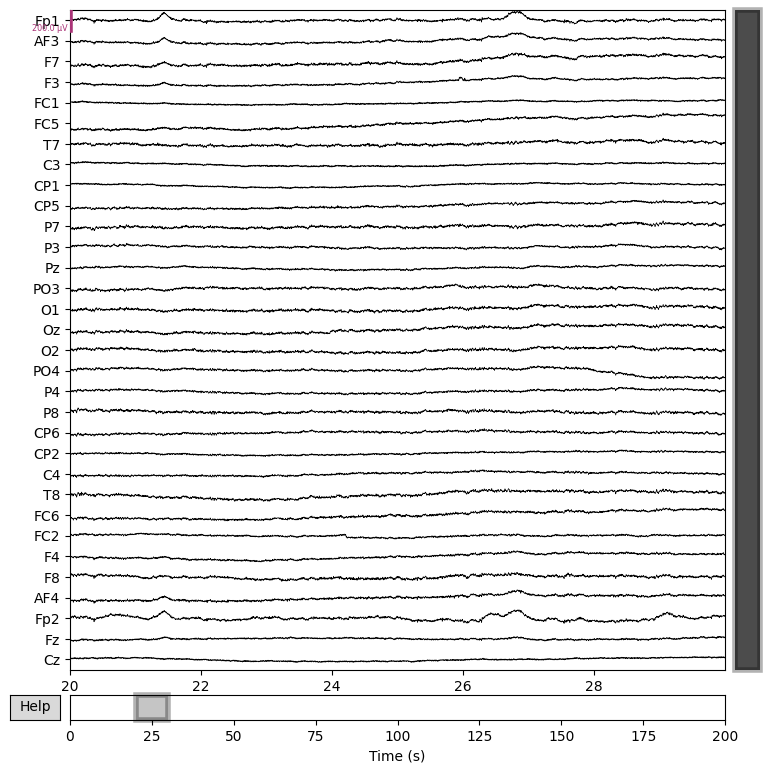

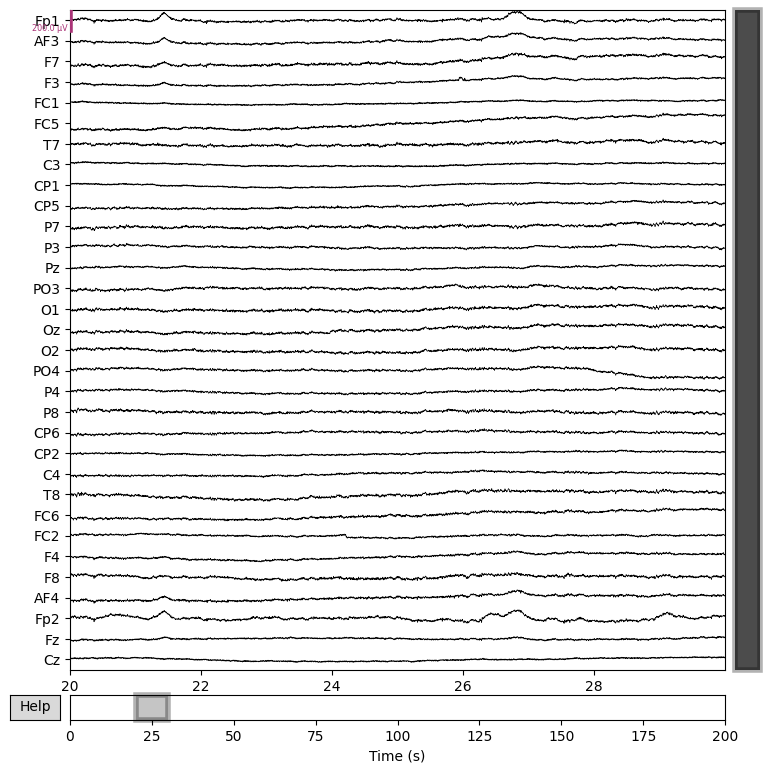

In [13]:
raw_off.plot(duration=10, start=20, picks=raw_off.ch_names[:32],
             n_channels=32, scalings=dict(eeg=100e-6))

In [14]:
for raw in (raw_off, raw_on):
    raw.pick(raw.ch_names[:32])
    raw.set_eeg_reference("average")
    raw.filter(l_freq=1, h_freq=45)

print(len(raw_off.ch_names), len(raw_on.ch_names))

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 1691 samples (3.303 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain 

In [15]:
from scipy.integrate import trapezoid

BANDS = {"low_beta": (13, 20), "high_beta": (20, 30)}
CENTRAL = ["C3", "Cz", "C4"]

def band_powers(raw):
    psd = raw.compute_psd(method="welch", fmin=1, fmax=45,
                          n_fft=int(2 * raw.info["sfreq"]),
                          picks=CENTRAL, verbose=False)
    freqs = psd.freqs
    data = psd.get_data().mean(axis=0)        # average over the 3 channels
    total = trapezoid(data, freqs)            # all power from 1 to 45 Hz
    out = {}
    for name, (lo, hi) in BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        power = trapezoid(data[mask], freqs[mask])
        out[name] = power                     # absolute power
        out[name + "_rel"] = power / total    # share of total power
    return out

print("OFF:", band_powers(raw_off))
print("ON: ", band_powers(raw_on))

OFF: {'low_beta': np.float64(9.938630299734482e-13), 'low_beta_rel': np.float64(0.07516006014791066), 'high_beta': np.float64(1.899560110463312e-12), 'high_beta_rel': np.float64(0.1436526441282443)}
ON:  {'low_beta': np.float64(8.809017051243278e-13), 'low_beta_rel': np.float64(0.06471116095751082), 'high_beta': np.float64(2.324706817311361e-12), 'high_beta_rel': np.float64(0.17077328396455574)}


In [16]:
on.download(dataset="ds002778", target_dir="ds002778")

🌍 Preparing to download ds002778 …
📥 Checking 328 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds002778 (downloaded 309 files and 520.2 MB).


In [17]:
import pandas as pd

mne.set_log_level("WARNING")
SCALP = list(raw_off.ch_names)       # the 32 scalp channels, from the cleaned recording
rows, failed = [], []

for sub_dir in sorted(Path("ds002778").glob("sub-*")):
    group = "control" if sub_dir.name.startswith("sub-hc") else "pd"
    for ses_dir in sorted(sub_dir.glob("ses-*")):
        files = list(ses_dir.rglob("*_eeg.bdf"))
        if not files:
            failed.append((sub_dir.name, ses_dir.name, "no .bdf file"))
            continue
        try:
            raw = mne.io.read_raw_bdf(files[0], preload=True)
            raw.pick(SCALP)
            raw.set_eeg_reference("average")
            raw.filter(l_freq=1, h_freq=45)
            result = band_powers(raw)
            rows.append({"subject": sub_dir.name, "group": group,
                         "session": ses_dir.name.replace("ses-", ""), **result})
        except Exception as e:
            failed.append((sub_dir.name, ses_dir.name, str(e)[:80]))

df = pd.DataFrame(rows)
df.to_csv("band_power.csv", index=False)
print(len(df), "recordings processed (expected 46)")
print("Failed:", failed)
print(df[["subject", "group", "session", "low_beta_rel", "high_beta_rel"]].round(4).to_string())

46 recordings processed (expected 46)
Failed: []
     subject    group session  low_beta_rel  high_beta_rel
0    sub-hc1  control      hc        0.0922         0.1292
1   sub-hc10  control      hc        0.1858         0.1489
2   sub-hc18  control      hc        0.1012         0.0644
3    sub-hc2  control      hc        0.0993         0.0944
4   sub-hc20  control      hc        0.0780         0.1190
5   sub-hc21  control      hc        0.0955         0.0659
6   sub-hc24  control      hc        0.0575         0.0343
7   sub-hc25  control      hc        0.0700         0.1507
8   sub-hc29  control      hc        0.0881         0.0566
9   sub-hc30  control      hc        0.0407         0.0244
10  sub-hc31  control      hc        0.1298         0.1733
11  sub-hc32  control      hc        0.1757         0.3662
12  sub-hc33  control      hc        0.1057         0.1566
13   sub-hc4  control      hc        0.1331         0.1417
14   sub-hc7  control      hc        0.0986         0.0665
15   su

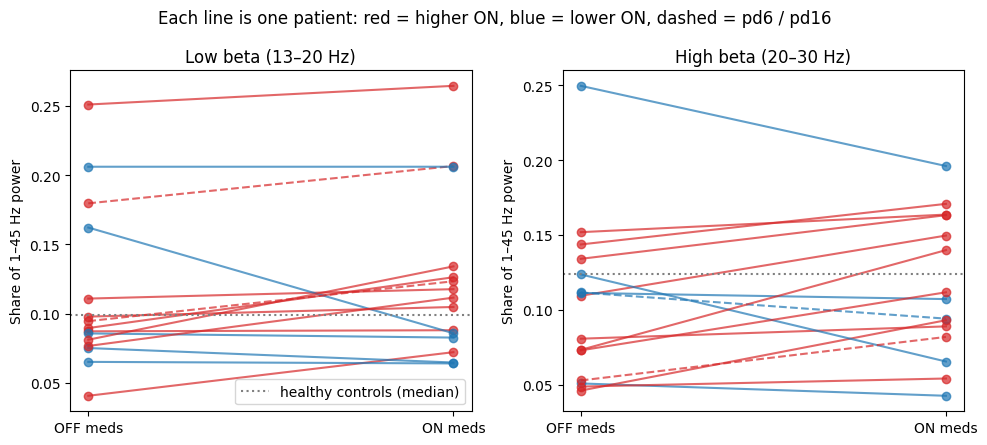

In [18]:
import matplotlib.pyplot as plt

pdf = df[df.group == "pd"]
ctrl = df[df.group == "control"]
QUIRKY = ["sub-pd6", "sub-pd16"]          # patients with preprocessed ON files

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, col, title in zip(axes,
                          ["low_beta_rel", "high_beta_rel"],
                          ["Low beta (13–20 Hz)", "High beta (20–30 Hz)"]):
    for sub, g in pdf.groupby("subject"):
        off = g.loc[g.session == "off", col].iloc[0]
        on = g.loc[g.session == "on", col].iloc[0]
        color = "tab:red" if on > off else "tab:blue"
        style = "--" if sub in QUIRKY else "-"
        ax.plot([0, 1], [off, on], style, color=color, alpha=0.7, marker="o")
    ax.axhline(ctrl[col].median(), color="gray", linestyle=":",
               label="healthy controls (median)")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["OFF meds", "ON meds"])
    ax.set_title(title)
    ax.set_ylabel("Share of 1–45 Hz power")

axes[0].legend()
plt.suptitle("Each line is one patient: red = higher ON, blue = lower ON, dashed = pd6 / pd16")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(0)

def boot_ci_paired(diff, n=10000):
    means = [rng.choice(diff, len(diff)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

def boot_ci_groups(a, b, n=10000):
    diffs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return np.percentile(diffs, [2.5, 97.5])

def analyze(df, exclude=()):
    d = df[~df.subject.isin(exclude)]
    pdf, ctrl = d[d.group == "pd"], d[d.group == "control"]
    off = pdf[pdf.session == "off"].set_index("subject").sort_index()
    on = pdf[pdf.session == "on"].set_index("subject").sort_index()
    rows = []
    for col in ["low_beta_rel", "high_beta_rel"]:
        diff = (on[col] - off[col]).values
        lo, hi = boot_ci_paired(diff)
        rows.append({"test": f"{col}: ON - OFF (paired)", "n": len(diff),
                     "mean_diff": diff.mean(), "ci_low": lo, "ci_high": hi,
                     "effect_size": diff.mean() / diff.std(ddof=1),
                     "p": stats.wilcoxon(on[col], off[col]).pvalue})
    for col in ["low_beta_rel", "high_beta_rel"]:
        a, b = off[col].values, ctrl[col].values
        lo, hi = boot_ci_groups(a, b)
        pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1))
                         / (len(a) + len(b) - 2))
        rows.append({"test": f"{col}: PD-OFF - controls", "n": f"{len(a)} vs {len(b)}",
                     "mean_diff": a.mean() - b.mean(), "ci_low": lo, "ci_high": hi,
                     "effect_size": (a.mean() - b.mean()) / pooled,
                     "p": stats.mannwhitneyu(a, b).pvalue})
    res = pd.DataFrame(rows)
    res["p_fdr"] = multipletests(res["p"], method="fdr_bh")[1]
    return res

for label, excl in [("ALL PATIENTS", ()),
                    ("WITHOUT pd6 and pd16", ("sub-pd6", "sub-pd16"))]:
    print(label)
    print(analyze(df, excl).round(4).to_string(index=False))
    print()

ALL PATIENTS
                            test        n  mean_diff  ci_low  ci_high  effect_size      p  p_fdr
 low_beta_rel: ON - OFF (paired)       15     0.0099 -0.0064   0.0233       0.3301 0.0946 0.3784
high_beta_rel: ON - OFF (paired)       15     0.0108 -0.0076   0.0274       0.3063 0.2293 0.4586
 low_beta_rel: PD-OFF - controls 15 vs 16     0.0089 -0.0238   0.0439       0.1805 0.7369 0.7369
high_beta_rel: PD-OFF - controls 15 vs 16    -0.0253 -0.0772   0.0230      -0.3397 0.4408 0.5878

WITHOUT pd6 and pd16
                            test        n  mean_diff  ci_low  ci_high  effect_size      p  p_fdr
 low_beta_rel: ON - OFF (paired)       13     0.0072 -0.0104   0.0223       0.2274 0.2439 0.4878
high_beta_rel: ON - OFF (paired)       13     0.0115 -0.0087   0.0292       0.3143 0.2439 0.4878
 low_beta_rel: PD-OFF - controls 13 vs 16     0.0053 -0.0294   0.0442       0.1071 0.5538 0.5836
high_beta_rel: PD-OFF - controls 13 vs 16    -0.0220 -0.0746   0.0280      -0.2868 0.5836 0.

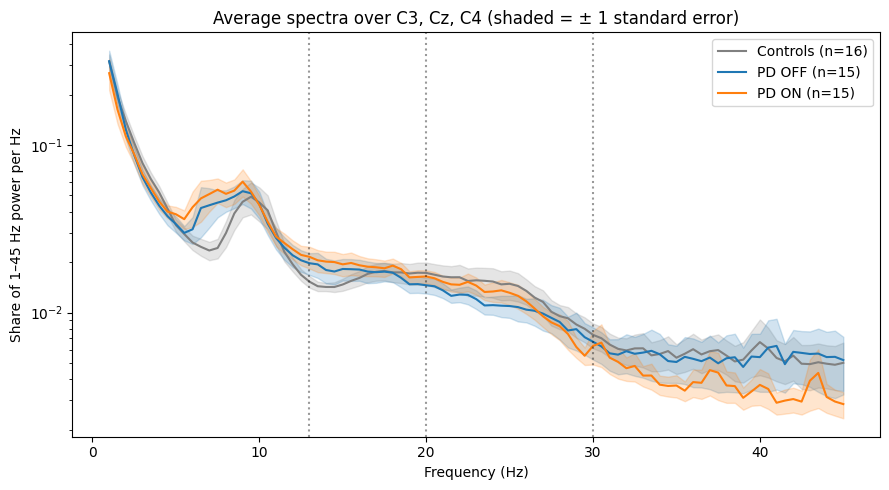

In [20]:
spectra = {"Controls": [], "PD OFF": [], "PD ON": []}
group_of = {"ses-hc": "Controls", "ses-off": "PD OFF", "ses-on": "PD ON"}

for sub_dir in sorted(Path("ds002778").glob("sub-*")):
    for ses_dir in sorted(sub_dir.glob("ses-*")):
        file = next(ses_dir.rglob("*_eeg.bdf"))
        raw = mne.io.read_raw_bdf(file, preload=True)
        raw.pick(SCALP)
        raw.set_eeg_reference("average")
        raw.filter(l_freq=1, h_freq=45)
        psd = raw.compute_psd(method="welch", fmin=1, fmax=45,
                              n_fft=int(2 * raw.info["sfreq"]),
                              picks=CENTRAL, verbose=False)
        freqs = psd.freqs
        spec = psd.get_data().mean(axis=0)             # average over C3, Cz, C4
        spectra[group_of[ses_dir.name]].append(spec / trapezoid(spec, freqs))

colors = {"Controls": "gray", "PD OFF": "tab:blue", "PD ON": "tab:orange"}
fig, ax = plt.subplots(figsize=(9, 5))
for name, arr in spectra.items():
    arr = np.array(arr)
    mean = arr.mean(axis=0)
    sem = arr.std(axis=0, ddof=1) / np.sqrt(len(arr))
    ax.semilogy(freqs, mean, color=colors[name], label=f"{name} (n={len(arr)})")
    ax.fill_between(freqs, mean - sem, mean + sem, color=colors[name], alpha=0.2)

for edge in (13, 20, 30):
    ax.axvline(edge, color="black", linestyle=":", alpha=0.4)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Share of 1–45 Hz power per Hz")
ax.set_title("Average spectra over C3, Cz, C4 (shaded = ± 1 standard error)")
ax.legend()
plt.tight_layout()
plt.savefig("group_spectra.png", dpi=200)
plt.show()

In [21]:
def rel_band(arrs, lo, hi):
    mask = (freqs >= lo) & (freqs < hi)
    return np.array([trapezoid(a[mask], freqs[mask]) for a in arrs])

def cohens_d(a, b):
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1))
                     / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

rows = []
for band_name, (lo, hi) in {"theta 4-8 Hz": (4, 8), "6-8 Hz": (6, 8)}.items():
    ctrl = rel_band(spectra["Controls"], lo, hi)
    off = rel_band(spectra["PD OFF"], lo, hi)
    on = rel_band(spectra["PD ON"], lo, hi)

    for label, a, b in [("PD OFF - controls", off, ctrl), ("PD ON - controls", on, ctrl)]:
        ci_lo, ci_hi = boot_ci_groups(a, b)
        rows.append({"band": band_name, "test": label,
                     "mean_diff": a.mean() - b.mean(), "ci_low": ci_lo, "ci_high": ci_hi,
                     "effect_size": cohens_d(a, b),
                     "p": stats.mannwhitneyu(a, b).pvalue})

    diff = on - off
    ci_lo, ci_hi = boot_ci_paired(diff)
    rows.append({"band": band_name, "test": "ON - OFF (paired)",
                 "mean_diff": diff.mean(), "ci_low": ci_lo, "ci_high": ci_hi,
                 "effect_size": diff.mean() / diff.std(ddof=1),
                 "p": stats.wilcoxon(on, off).pvalue})

res = pd.DataFrame(rows)
res["p_fdr"] = multipletests(res["p"], method="fdr_bh")[1]
print(res.round(4).to_string(index=False))

        band              test  mean_diff  ci_low  ci_high  effect_size      p  p_fdr
theta 4-8 Hz PD OFF - controls     0.0230 -0.0135   0.0663       0.3932 0.2599 0.2599
theta 4-8 Hz  PD ON - controls     0.0448  0.0079   0.0918       0.7212 0.0459 0.0551
theta 4-8 Hz ON - OFF (paired)     0.0218  0.0094   0.0340       0.8650 0.0043 0.0134
      6-8 Hz PD OFF - controls     0.0254  0.0008   0.0621       0.5689 0.0344 0.0517
      6-8 Hz  PD ON - controls     0.0370  0.0111   0.0716       0.8285 0.0047 0.0134
      6-8 Hz ON - OFF (paired)     0.0116  0.0048   0.0193       0.7742 0.0067 0.0134
